# K-medoids (heuristic)

In [2]:
import time
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances
from sklearn_extra.cluster._k_medoids import KMedoids

## Data

In [3]:
iris = load_iris()
X_raw = iris.data
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0, ddof=1)
y = iris.target

## K-medoids (heuristic)

In [4]:
%%time

k = 3
kmedoids = KMedoids(n_clusters=k, method="pam", init="k-medoids++", random_state=42)
kmedoids.fit(X)
y_pred = kmedoids.labels_
medoid_indices = kmedoids.medoid_indices_

CPU times: user 24.5 ms, sys: 60 μs, total: 24.5 ms
Wall time: 24.4 ms


/opt/python/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


Here is the visualisation (after a PCA to have a two-dimensional representation):

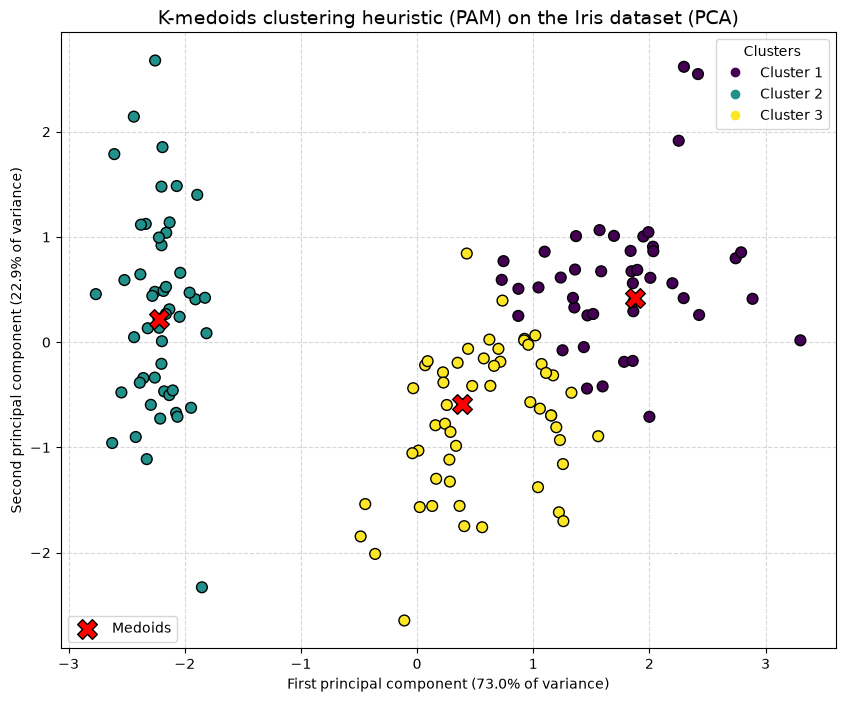

In [5]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)
var = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_2d[:, 0], 
    X_2d[:, 1], 
    c=y_pred, 
    cmap="viridis",
    s=60, 
    edgecolor="k", 
    zorder=2
)
plt.scatter(
    X_2d[medoid_indices, 0], 
    X_2d[medoid_indices, 1],
    c="red", 
    marker="X", 
    s=200, 
    edgecolor="black",
    label="Medoids", 
    zorder=3
)
handles, _ = scatter.legend_elements()
legend_clusters = plt.legend(
    handles, 
    [f"Cluster {i+1}" for i in range(k)],
    loc="upper right", 
    title="Clusters"
)
plt.gca().add_artist(legend_clusters)
plt.legend(loc="lower left")
plt.title("K-medoids clustering heuristic (PAM) on the Iris dataset (PCA)", fontsize=14)
plt.xlabel(f"First principal component ({var[0]:.1f}% of variance)")
plt.ylabel(f"Second principal component ({var[1]:.1f}% of variance)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("iris_heuristic_kmedoids.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:

# pca = PCA(n_components=2)
# X_2d = pca.fit_transform(X)


# plt.figure(figsize=(10, 8))

# scatter = plt.scatter(
#     X_2d[:, 0], X_2d[:, 1], c=y_pred, cmap='viridis', s=60, edgecolor='k', zorder=2
# )

# plt.scatter(
#     X_2d[medoid_indices, 0],
#     X_2d[medoid_indices, 1],
#     c='red',
#     marker='X',
#     s=200,
#     edgecolor='black',
#     label='Medoids',
#     zorder=3,
# )

# plt.title(
#     "K-Medoid clustering heuristic with the Iris dataset (PCA)", fontsize=14
# )
# plt.xlabel("First principal component (PCA 1)")
# plt.ylabel("Second principal component (PCA 2)")
# plt.legend()
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.savefig("iris_heuristic_kmedoids.png")
# plt.show()